In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

## **1) ΔΕΔΟΜΕΝΑ ΚΑΙ ΠΡΟΕΤΟΙΜΑΣΙΑ**
### **ΦΟΡΤΩΣΗ ΚΑΙ ΒΑΣΙΚΑ ΣΤΟΙΧΕΙΑ ΔΕΔΟΜΕΝΩΝ**

In [120]:
#Διαβάζει τα δεδομένα 
df = pd.read_csv("data_Fraud.csv")

In [121]:
df.head()

,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,...,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
0,1990,1009,NaN,0,10.047,3.736,32.335,6.262,0.002,30.633,...,0.312448,0.095082,0.082631,-0.019761,1,0.413170,0.873555,0.167620,0.161961,-0.042140
1,1990,1011,NaN,0,1.247,0.803,7.784,0.667,0.171,1.125,...,0.315904,0.188832,-0.211389,-0.117832,1,0.157887,0.745139,-0.428957,-0.157888,0.100228
2,1990,1017,NaN,0,55.040,3.601,118.120,44.393,3.132,107.343,...,0.605342,0.097551,-0.105780,0.091206,1,2.231337,1.015131,0.394768,0.063681,0.066348
3,1990,1021,NaN,0,24.684,3.948,34.591,7.751,0.411,31.214,...,0.793068,-0.005725,-0.249704,0.017545,1,1.043582,1.026261,0.094822,0.088347,-0.017358
4,1990,1028,NaN,0,17.325,3.520,27.542,-12.142,1.017,32.662,...,0.869182,-0.231536,-1.674893,-0.466667,0,-1.602508,0.598443,-0.942379,-0.700821,0.130349


In [122]:
#Τα δεδομένα έχουν 146045 γραμμές και 46 στήλες
print(df.shape) 

(146045, 46)


In [123]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 146045 entries, 0 to 146044
Data columns (total 46 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   fyear        146045 non-null  int64  
 1   gvkey        146045 non-null  int64  
 2   p_aaer       964 non-null     float64
 3   misstate     146045 non-null  int64  
 4   act          146045 non-null  float64
 5   ap           146045 non-null  float64
 6   at           146045 non-null  float64
 7   ceq          146045 non-null  float64
 8   che          146045 non-null  float64
 9   cogs         146045 non-null  float64
 10  csho         146045 non-null  float64
 11  dlc          146045 non-null  float64
 12  dltis        146045 non-null  float64
 13  dltt         146045 non-null  float64
 14  dp           146045 non-null  float64
 15  ib           146045 non-null  float64
 16  invt         146045 non-null  float64
 17  ivao         146045 non-null  float64
 18  ivst         146045 non-null  float

In [124]:
#Οι στήλες του dataset είναι οι εξής:
df.columns

Index(['fyear', 'gvkey', 'p_aaer', 'misstate', 'act', 'ap', 'at', 'ceq', 'che',
       'cogs', 'csho', 'dlc', 'dltis', 'dltt', 'dp', 'ib', 'invt', 'ivao',
       'ivst', 'lct', 'lt', 'ni', 'ppegt', 'pstk', 're', 'rect', 'sale',
       'sstk', 'txp', 'txt', 'xint', 'prcc_f', 'dch_wc', 'ch_rsst', 'dch_rec',
       'dch_inv', 'soft_assets', 'ch_cs', 'ch_cm', 'ch_roa', 'issue', 'bm',
       'dpi', 'reoa', 'EBIT', 'ch_fcf'],
      dtype='str')

In [125]:
#Το εύρος των ετών είναι από το 1990 εως το 2014
print(df['fyear'].min(), "-", df['fyear'].max())

1990 - 2014


In [126]:
#Περιγραφικά στατιστιά στοιχεία για το dataset
df.describe() 

,fyear,gvkey,p_aaer,misstate,act,ap,at,ceq,che,cogs,...,soft_assets,ch_cs,ch_cm,ch_roa,issue,bm,dpi,reoa,EBIT,ch_fcf
count,146045.000000,146045.000000,964.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,146045.000000,...,145453.000000,130127.000000,128938.000000,133367.000000,146045.000000,146027.000000,136817.000000,145454.000000,145454.000000,140638.000000
mean,2002.011702,54243.435516,2503.840249,0.006601,737.847759,181.993488,2374.041576,887.126243,218.657186,1302.280756,...,0.499790,0.185169,-0.090980,-0.010208,0.863487,0.466137,1.042207,-3.191197,-0.238754,-0.008842
std,6.959894,59937.455765,912.093250,0.080976,3744.542368,1047.546104,11957.736980,5056.948150,1330.490185,7870.665783,...,0.274129,1.383354,2.844807,0.379574,0.343333,1.314661,0.495286,12.932219,1.059134,0.548216
min,1990.000000,1004.000000,371.000000,0.000000,-0.254000,0.000000,0.000000,-25560.000000,-34.000000,-366.645000,...,0.004515,-6.484197,-17.359699,-1.671565,0.000000,-7.034304,0.151757,-89.013245,-7.016393,-2.980601
25%,1996.000000,10658.000000,1803.000000,0.000000,8.277000,1.151000,18.281000,6.337000,1.144000,6.795000,...,0.270023,-0.073635,-0.260164,-0.058635,1.000000,0.191546,0.854248,-0.894633,-0.128135,-0.123402
50%,2002.000000,25088.000000,2620.500000,0.000000,47.501000,6.462000,105.346000,47.308000,9.373000,53.382000,...,0.524640,0.067918,-0.023205,-0.001893,1.000000,0.442172,0.974302,-0.008046,0.043701,-0.026155
75%,2008.000000,66586.000000,3180.000000,0.000000,249.832000,42.259000,672.929000,271.547000,60.286000,372.730000,...,0.726663,0.250237,0.139960,0.042188,1.000000,0.805320,1.097582,0.229724,0.108059,0.062294
max,2014.000000,317264.000000,3996.000000,1.000000,152629.000000,39903.000000,410074.000000,284434.000000,85709.000000,435726.253000,...,0.993599,9.600000,16.573810,1.621628,1.000000,4.937457,4.036458,0.784573,0.550619,4.061810


In [127]:
#Το ποσοστό της κάθε κλάσης στην στήλη misstate (0 = No Fraud, 1 = Fraud)
print(df['misstate'].value_counts())
print(df['misstate'].value_counts(normalize=True) * 100) #εμφανιση σε ποσοστο

misstate
0    145081
1       964
Name: count, dtype: int64
misstate
0    99.339929
1     0.660071
Name: proportion, dtype: float64


In [128]:
#Μου δείχνει πόσες παρατηρήσεις έχει κάθε έτος και πόσες από αυτές είναι fraud (misstate = 1)
print(df.groupby("fyear")["misstate"].agg(["count","sum"]))

       count  sum
fyear            
1990    4582   15
1991    4713   27
1992    4970   26
1993    5377   30
1994    5684   23
1995    6230   22
1996    6745   33
1997    6789   42
1998    6716   56
1999    6828   73
2000    6752   86
2001    6362   81
2002    6067   77
2003    5981   69
2004    5934   58
2005    5863   45
2006    5908   33
2007    5868   30
2008    5612   26
2009    5367   31
2010    5389   26
2011    5404   21
2012    5630   19
2013    5647   11
2014    5627    4


### **ΟΠΤΙΚΟΠΟΙΗΣΗ ΤΟΥ ΣΥΝΟΛΟΥ ΔΕΔΟΜΕΝΩΝ - EDA**

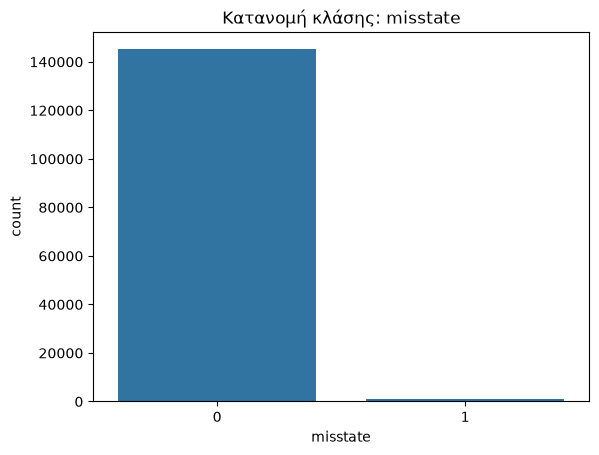

In [129]:
#Κατανομή κλάσης misstate
sns.countplot(x='misstate', data=df)
plt.title('Κατανομή κλάσης: misstate')
plt.show()

In [130]:
#Ποσοστό απάτης ανά χρονιά 
print(df.groupby('fyear')['misstate'].mean() * 100)

fyear
1990    0.327368
1991    0.572884
1992    0.523139
1993    0.557932
1994    0.404645
1995    0.353130
1996    0.489251
1997    0.618648
1998    0.833830
1999    1.069127
2000    1.273697
2001    1.273185
2002    1.269161
2003    1.153653
2004    0.977418
2005    0.767525
2006    0.558565
2007    0.511247
2008    0.463293
2009    0.577604
2010    0.482464
2011    0.388601
2012    0.337478
2013    0.194794
2014    0.071086
Name: misstate, dtype: float64


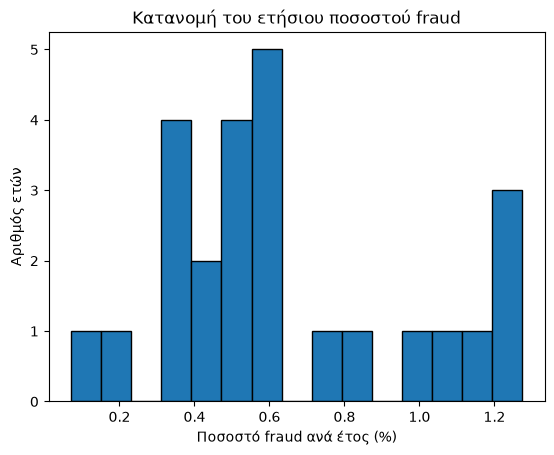

In [131]:
fraud_rate_by_year = df.groupby('fyear')['misstate'].mean() * 100

plt.hist(fraud_rate_by_year, bins=15, edgecolor='black')
plt.xlabel('Ποσοστό fraud ανά έτος (%)')
plt.ylabel('Αριθμός ετών')
plt.title('Κατανομή του ετήσιου ποσοστού fraud')
plt.show()

##### Το παραπάνω διάγραμμα μας δείχνει το πλήθος των ετών που αντιστοιχεί σε κάθε fraud rate. Παρατηρούμε ότι το πιο σύνηθες ποσοστό απάτης το οποίο αντιστοιχεί σε 5 διαφορετικά έτη είναι περίπου 0,6%

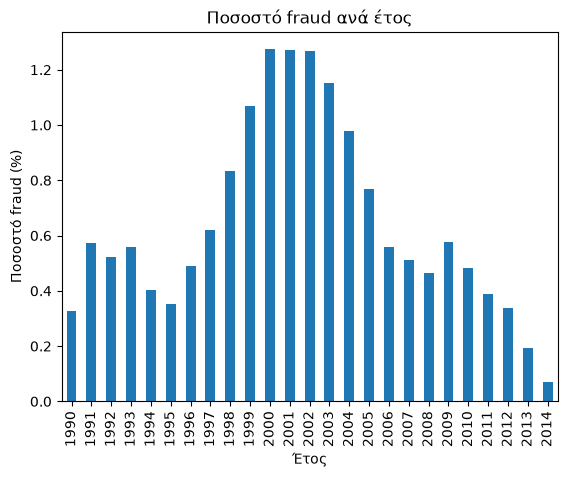

In [132]:
fraud_rate_by_year.plot(kind='bar')
plt.xlabel('Έτος')
plt.ylabel('Ποσοστό fraud (%)')
plt.title('Ποσοστό fraud ανά έτος')
plt.show()

##### Το παραπάνω διάγραμμα απεικονίζει για κάθε έτος ποιό είναι το ποσοστό απάτης. Παρατηρούμε πως τις χρονιές 2000-2002 παρατηρούνται τα μεγαλύτερα ποσοσστά απάτης ύψους 1,2% περίπου και στη συνέχεια μειώνονται.

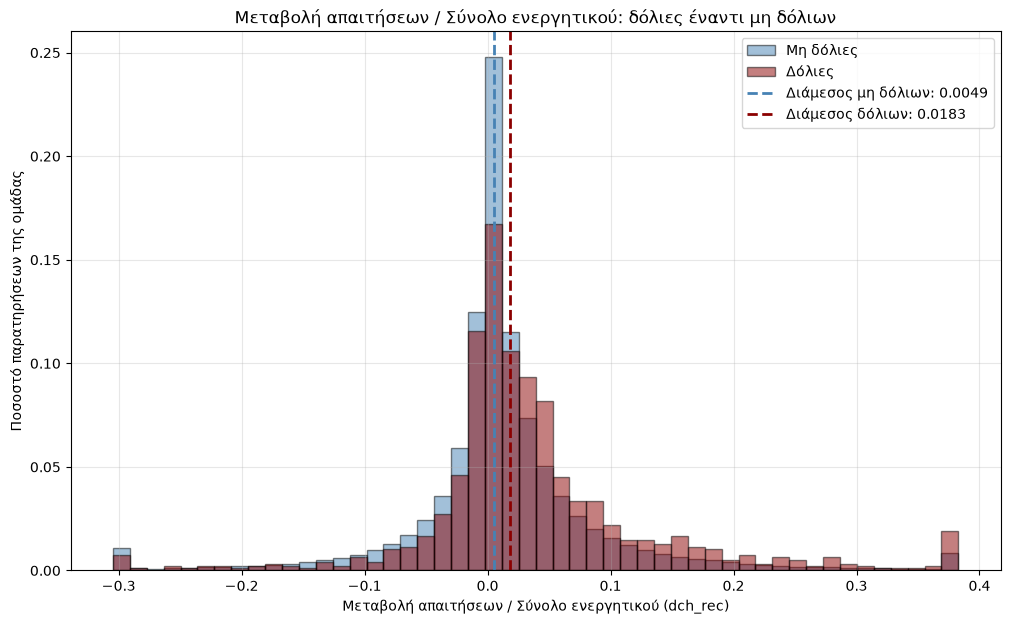

In [133]:
fraud = df.loc[df['misstate'] == 1, 'dch_rec'].dropna()
non_fraud = df.loc[df['misstate'] == 0, 'dch_rec'].dropna()

plt.figure(figsize=(12, 7))
plt.hist(non_fraud, bins=50,
         weights=np.ones(len(non_fraud)) / len(non_fraud),
         alpha=0.5, color='steelblue', edgecolor='black', label='Μη δόλιες')
plt.hist(fraud, bins=50,
         weights=np.ones(len(fraud)) / len(fraud),
         alpha=0.5, color='darkred', edgecolor='black', label='Δόλιες')

plt.axvline(non_fraud.median(), color='steelblue', linestyle='--', linewidth=2,
            label=f'Διάμεσος μη δόλιων: {non_fraud.median():.4f}')
plt.axvline(fraud.median(), color='darkred', linestyle='--', linewidth=2,
            label=f'Διάμεσος δόλιων: {fraud.median():.4f}')

plt.title('Μεταβολή απαιτήσεων / Σύνολο ενεργητικού: δόλιες έναντι μη δόλιων')
plt.xlabel('Μεταβολή απαιτήσεων / Σύνολο ενεργητικού (dch_rec)')
plt.ylabel('Ποσοστό παρατηρήσεων της ομάδας')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Στο παραπάνω διάγραμμα παρατηρούμε πως η διάμεσος των μη δολιων  επιχειρήσεων ανέρχεται σε 0,0065 έναντι των δόλιων που είναι τετραπάσια φτάνοντας το 0,0209. Αυτό σημαίνει πως το 50% των παρατηρήσεων των δόλιων εταιρειών έχουν μεταβολή απαιτήσεων/σύνολο ενεργητικού κάτω απο 0,0209 και αντίστοιχα οι μη δόλιες κάτω από 0,0065

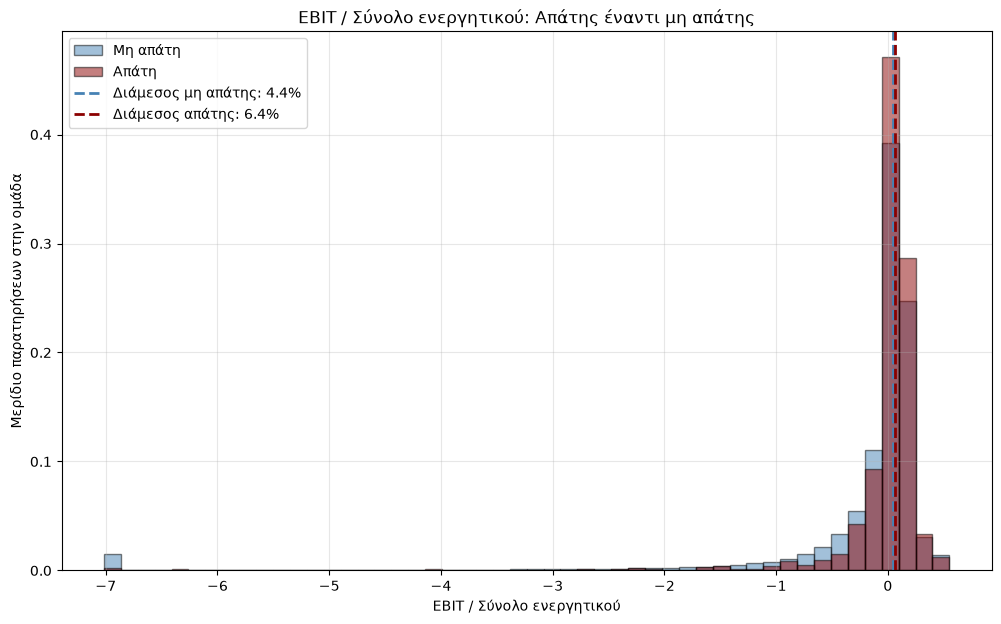

In [134]:
fraud = df.loc[df['misstate'] == 1, 'EBIT'].dropna()
non_fraud = df.loc[df['misstate'] == 0, 'EBIT'].dropna()

plt.figure(figsize=(12, 7))
plt.hist(non_fraud, bins=50,
         weights=np.ones(len(non_fraud)) / len(non_fraud),
         alpha=0.5, color='steelblue', edgecolor='black', label='Μη απάτη')
plt.hist(fraud, bins=50,
         weights=np.ones(len(fraud)) / len(fraud),
         alpha=0.5, color='darkred', edgecolor='black', label='Απάτη')

plt.axvline(non_fraud.median(), color='steelblue', linestyle='--', linewidth=2,
            label=f'Διάμεσος μη απάτης: {non_fraud.median():.1%}')
plt.axvline(fraud.median(), color='darkred', linestyle='--', linewidth=2,
            label=f'Διάμεσος απάτης: {fraud.median():.1%}')

plt.title('EBIT / Σύνολο ενεργητικού: Απάτης έναντι μη απάτης')
plt.xlabel('EBIT / Σύνολο ενεργητικού')
plt.ylabel('Μερίδιο παρατηρήσεων στην ομάδα')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Στο παραπάνω διάγραμμα η διάμεσος των δόλιων και μη επιχειρήσεων έχουν μια πολύ μικρή διαφορά της τάξης του 2%, όμως αυτή των δόλιων επιχειρήσεων είναι μεγαλύτερη (6,4 έναντι 4,4). Αυτο σημαίνει πως για το 50% των μη δόλιων παρατηρήσεων ο λόγος EBIT/Σύνολο ενεργητιού είναι κάτω από τα επίπεδα του 4,4%, δηλαδή για κάθε 100$ συνόλου του ενεργητικού υπάρχει κέρφοφορία έως και  4,4$ ενώ αντίστοιχα για το 50% των δόλιων για κάθε 100$ συνόλου του ενεργητικού υπάρχει κέρφοφορία έως και 6,4$

C:\Users\Φαίδρα\AppData\Local\Temp\ipykernel_20408\594244258.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='misstate', y='fyear', palette='Set2')


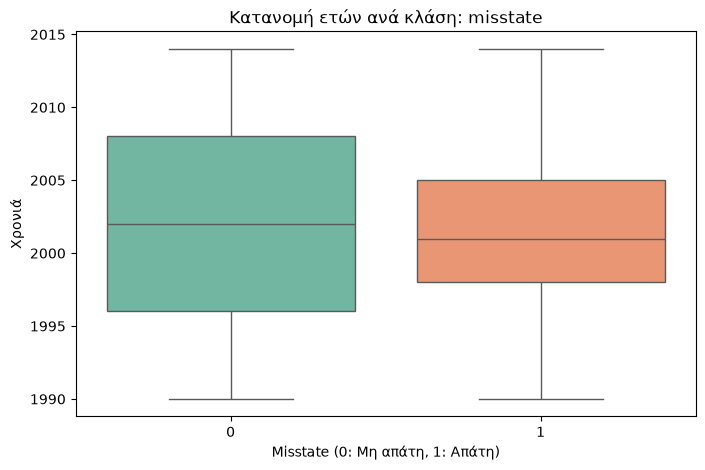

In [135]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='misstate', y='fyear', palette='Set2')
plt.title('Κατανομή ετών ανά κλάση: misstate')
plt.xlabel('Misstate (0: Μη απάτη, 1: Απάτη)')
plt.ylabel('Χρονιά')
plt.show()

#### Παρατηρούμε ότι για τις εταιρείες που έχουν διπράξει απάτη γύρω από τη χρονιά του 2000 υπάρχει μικρή διακύμανση και διασπορά των παρατηρήσεων 

## **ΚΑΘΑΡΙΣΜΟΣ ΔΕΔΟΜΕΝΩΝ**

In [136]:
#Αφαιρούμε τις παρατηρήσεις μετά το 2008 για να αποφύγουμε την επίδραση της χρηματοπιστωτικής κρίσης
df = df[df['fyear'] <= 2008].copy()
print (df.shape)
print (df['fyear'].min(), "-", df['fyear'].max())

(112981, 46)
1990 - 2008


In [137]:
#Το ποσοστό της κάθε κλάσης στην στήλη misstate (0 = No Fraud, 1 = Fraud) μετά την αφαίρεση των παρατηρήσεων μετά το 2008
print(df['misstate'].value_counts())
print(df['misstate'].value_counts(normalize=True) * 100) #εμφανιση σε ποσοστο

misstate
0    112129
1       852
Name: count, dtype: int64
misstate
0    99.245891
1     0.754109
Name: proportion, dtype: float64


In [138]:
# Ποσοστό ελλειπουσών τιμών ανά στήλη (%)
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False).head(10))

p_aaer     99.25
ch_cm      11.06
ch_cs      10.30
ch_roa      8.49
dpi         5.36
ch_fcf      3.37
ch_rsst     2.94
dch_wc      2.88
dch_rec     2.82
dch_inv     2.77
dtype: float64


In [139]:
# Στήλες που ελέγχουμε: όλες εκτός από p_aaer (υπάρχει μόνο στις απάτες)
check_cols = df.columns.drop('p_aaer')

# Πόσα κενά έχει κάθε γραμμή
missing_per_row = df[check_cols].isnull().sum(axis=1)

# Όριο: οι μισές στήλες
half = len(check_cols) / 2

# True όταν η γραμμή έχει κενά σε πάνω από τις μισές στήλες
many_missing = missing_per_row > half

print("Στήλες που ελέγχονται:", len(check_cols))
print("Όριο (μισές στήλες):", half)
print("Γραμμές με κενά σε πάνω από τις μισές στήλες:", many_missing.sum())
print("Μέγιστος αριθμός κενών σε μία γραμμή:", missing_per_row.max())

Στήλες που ελέγχονται: 45
Όριο (μισές στήλες): 22.5
Γραμμές με κενά σε πάνω από τις μισές στήλες: 0
Μέγιστος αριθμός κενών σε μία γραμμή: 13


In [140]:
# Δεν περιλαμβάνουμε την μεταβλητη p_aaer καθώς υπάρχει μόνο στις γραμμές που ειναι fraud 
# Στήλες "missing_values_cols" που εντοπίσαμε ότι έχουν τα περισσότερα missing values
missing_values_cols = ['ch_cm', 'ch_cs', 'ch_roa', 'dpi', 'ch_fcf', 
               'ch_rsst', 'dch_wc', 'dch_rec', 'dch_inv']

# Πόσες γραμμές έχουν τουλάχιστον ένα missing σε αυτές τις στήλες
missing_values = df[missing_values_cols].isnull().any(axis=1)
print(f"Γραμμές με missing σε missing_values_cols: {missing_values.sum()} "
      f"({missing_values.mean()*100:.2f}%)\n")

# Εμφνανιση ποσοστού misstate=1 για τς γραμμές που έχουν missing value
print("Ποσοστό misstate=1 ανάλογα με missing status")
print(df.groupby(missing_values)['misstate'].mean() * 100) # ο μέσος όρος ειναι ο αριθμός των fraud αφου το misstate ειναι 0 ή 1.

Γραμμές με missing σε missing_values_cols: 14092 (12.47%)

Ποσοστό misstate=1 ανάλογα με missing status
False    0.811010
True     0.354811
Name: misstate, dtype: float64


In [141]:
#Έλεγχος για διπλότυπα στις στήλες gvkey και fyear
dups = df.duplicated(subset=['gvkey', 'fyear'], keep=False)
print(f"Διπλότυπα: {dups.sum()}")

Διπλότυπα: 0


In [142]:
# Ποια είναι η πρώτη χρονιά κάθε εταιρείας στο dataset
first_year = df['fyear'] == df.groupby('gvkey')['fyear'].transform('min')

# Πίνακας: γραμμές με/χωρίς ελλείπουσες τιμές × πρώτη χρονιά ή όχι
print(pd.crosstab(missing_values, first_year,
                  rownames=['Ελλείπουσες τιμές'], colnames=['Πρώτη χρονιά'],
                  margins=True))

Πρώτη χρονιά       False   True     All
Ελλείπουσες τιμές                      
False              90915   7974   98889
True                6447   7645   14092
All                97362  15619  112981


##### Ο παραπάνω πίνακας μας δείχνει πως από το σύνολο των ελλειπούσων τιμών (14092) οι 7645 (54%) αντιστοιχούν στο πρώτο έτος μιας επιχείρησης στο δείγμα όπου οι μεταβλητές που συμβολίζουν μεταβολή δεν μπορούν να υπολογιστούν.

In [143]:
# Μεγέθη που οικονομικά δεν μπορεί να είναι αρνητικά και χρησιμοποιούνται στα scores
non_negative_cols = ['at', 'act', 'lct', 'lt', 'sale', 'cogs', 'rect', 'invt',
               'che', 'ppegt', 'dp', 'dltt', 'ap', 'csho', 'prcc_f']

for col in non_negative_cols:
    negative = df[col] < 0
    print(col,
          "| αρνητικές:", negative.sum(),
          "| απάτες σε αυτές:", df.loc[negative, 'misstate'].sum())

at | αρνητικές: 0 | απάτες σε αυτές: 0
act | αρνητικές: 8 | απάτες σε αυτές: 0
lct | αρνητικές: 0 | απάτες σε αυτές: 0
lt | αρνητικές: 0 | απάτες σε αυτές: 0
sale | αρνητικές: 26 | απάτες σε αυτές: 0
cogs | αρνητικές: 14 | απάτες σε αυτές: 0
rect | αρνητικές: 4 | απάτες σε αυτές: 0
invt | αρνητικές: 1 | απάτες σε αυτές: 0
che | αρνητικές: 27 | απάτες σε αυτές: 0
ppegt | αρνητικές: 0 | απάτες σε αυτές: 0
dp | αρνητικές: 1 | απάτες σε αυτές: 0
dltt | αρνητικές: 0 | απάτες σε αυτές: 0
ap | αρνητικές: 0 | απάτες σε αυτές: 0
csho | αρνητικές: 0 | απάτες σε αυτές: 0
prcc_f | αρνητικές: 0 | απάτες σε αυτές: 0


In [144]:
# Έλεγχος παρατηρήσεων με μηδενικό σύνολο ενεργητικού
zero_at = df['at'] == 0

print("Γραμμές με at = 0:", zero_at.sum())
print("Από αυτές δόλιες:", df.loc[zero_at, 'misstate'].sum())

# Πόσες κενές τιμές έχουν οι δείκτες που διαιρούν με το σύνολο ενεργητικού
print(df.loc[zero_at, ['EBIT', 'reoa', 'soft_assets']].isnull().sum())

Γραμμές με at = 0: 391
Από αυτές δόλιες: 0
EBIT           391
reoa           391
soft_assets    391
dtype: int64


##### Παρατηρούμε ότι το σύνολο ενεργητικού είναι μηδεν σε 391 παρατηρήσεις. Ωστόσο αποτελεί παρανομαστή στους δείκτες EBIΤ, reoa και soft_assets, συνεπώς σε 391 κελιά οι δείκτες αυτοί είναι κενοί καθώς δεν μπορεί να γίνει διαίρεση με το 0. Ωστόδο επειδή το πλήθος είναι μικρό οι παρατηρήσεις διατηρούνται.

## **FEATURE ENGINEERING**

### Κατασκευή δεικτών **Altman**, όσοι δεν υπάρχουν ήδη στο dataset. Από τους 5 δείκτες υπάρχουν οι 2, άρα κατασκευάζω 3.

In [145]:
# Δείκτες Altman (1968) - μόνο όσοι δεν υπάρχουν ήδη στο dataset
# X2 = reoa και X3 = EBIT υπάρχουν ήδη

df['alt_x1'] = (df['act'] - df['lct']) / df['at']          # Κεφάλαιο κίνησης / Ενεργητικό
df['alt_x4'] = (df['csho'] * df['prcc_f']) / df['lt']      # Χρημ. αξία ιδίων κεφαλαίων / Υποχρεώσεις
df['alt_x5'] = df['sale'] / df['at']                       # Πωλήσεις / Ενεργητικό

# Διαιρέσεις με το μηδέν δίνουν άπειρο (inf): τις μετατρέπουμε σε κενές τιμές
df = df.replace([np.inf, -np.inf], np.nan)

print(df[['alt_x1', 'alt_x4', 'alt_x5']].describe())
print(df[['alt_x1', 'alt_x4', 'alt_x5']].isnull().sum())

              alt_x1         alt_x4         alt_x5
count  112590.000000  112881.000000  112590.000000
mean       -1.738350      16.394760       1.274677
std       103.819767     411.560261      39.694176
min    -25968.517094       0.000000      -0.899225
25%         0.017452       0.801850       0.429859
50%         0.191235       2.072653       0.914773
75%         0.409253       6.149207       1.477736
max         1.000000   78458.526316   13203.000000
alt_x1    391
alt_x4    100
alt_x5    391
dtype: int64


### Κατασκευή δεικτών **Beneish**. Από τους δείκτες του ο DEPI υπάρχει ήδη στο σύνολο δεδομένων και ο SGAI δεν υπολογίζεται λόγω έλλειψης πληροφοριών

In [146]:
# Ταξινόμηση: κάθε εταιρεία με τις χρονιές της στη σειρά
df = df.sort_values(['gvkey', 'fyear'])

# Ποια είναι η προηγούμενη χρονιά της ίδιας εταιρείας;
prev_year = df.groupby('gvkey')['fyear'].shift(1)

# True όταν η προηγούμενη γραμμή δεν είναι η αμέσως προηγούμενη χρονιά
gap = prev_year != df['fyear'] - 1

# Μεγέθη που χρειάζονται για την προηγούμενη χρονιά
priv_year_cols = ['rect', 'sale', 'cogs', 'act', 'ppegt', 'at',
            'dltt', 'lct', 'che', 'dlc', 'txp']

for col in priv_year_cols:
    df[col + '_priv_year'] = df.groupby('gvkey')[col].shift(1)
    df.loc[gap, col + '_priv_year'] = np.nan

In [147]:
print(df[['gvkey', 'fyear', 'sale', 'sale_priv_year']].head(10))

        gvkey  fyear      sale  sale_priv_year
4582     1004   1991   422.657             NaN
38301    1004   1997   782.123             NaN
65386    1004   2001   638.721             NaN
71748    1004   2002   606.337         638.721
77815    1004   2003   651.958         606.337
83796    1004   2004   747.848         651.958
101501   1004   2007  1384.919             NaN
107369   1004   2008  1423.976        1384.919
0        1009   1990    40.522             NaN
4583     1009   1991    36.222          40.522


In [148]:
# Beneish (1999) - DEPI υπάρχει ήδη (dpi), SGAI δεν υπολογίζεται

# Μηδενικοί παρονομαστές -> κενές τιμές, πριν τις διαιρέσεις
sale     = df['sale'].replace(0, np.nan)
sale_priv_year = df['sale_priv_year'].replace(0, np.nan)
at       = df['at'].replace(0, np.nan)
at_priv_year   = df['at_priv_year'].replace(0, np.nan)

# DSRI
df['ben_dsri'] = (df['rect'] / sale) / (df['rect_priv_year'] / sale_priv_year)

# GMI
gm = (df['sale'] - df['cogs']) / sale
gm_priv_year = (df['sale_priv_year'] - df['cogs_priv_year']) / sale_priv_year
df['ben_gmi'] = gm_priv_year / gm

# AQI
aq = 1 - (df['act'] + df['ppegt']) / at
aq_priv_year = 1 - (df['act_priv_year'] + df['ppegt_priv_year']) / at_priv_year
df['ben_aqi'] = aq / aq_priv_year
df.loc[aq_priv_year == 0, 'ben_aqi'] = 1      # Beneish (1999): μηδενικός παρονομαστής AQI -> 1

# SGI
df['ben_sgi'] = df['sale'] / sale_priv_year

# LVGI
lev = (df['dltt'] + df['lct']) / at
lev_priv_year = (df['dltt_priv_year'] + df['lct_priv_year']) / at_priv_year
df['ben_lvgi'] = lev / lev_priv_year

# TATA
d_act = df['act'] - df['act_priv_year']
d_che = df['che'] - df['che_priv_year']
d_lct = df['lct'] - df['lct_priv_year']
d_dlc = df['dlc'] - df['dlc_priv_year']
d_txp = df['txp'] - df['txp_priv_year']
df['ben_tata'] = ((d_act - d_che) - (d_lct - d_dlc - d_txp) - df['dp']) / at

df = df.replace([np.inf, -np.inf], np.nan)

In [149]:
ben_cols = ['ben_dsri', 'ben_gmi', 'ben_aqi', 'ben_sgi', 'ben_lvgi', 'ben_tata']
print(df[ben_cols].describe())
print(df[ben_cols].isnull().sum())

           ben_dsri        ben_gmi       ben_aqi       ben_sgi       ben_lvgi  \
count  85666.000000   87343.000000  9.206200e+04  88170.000000   91954.000000   
mean       2.445987      -1.314226  2.306805e+10      2.513354       4.143883   
std      107.492402     659.098585  8.189220e+12     82.453739     726.992191   
min     -622.621027 -192418.000000 -7.862387e+14    -49.285714       0.000000   
25%        0.828128       0.918875  6.678541e-01      0.959145       0.892640   
50%        0.985973       0.997752  9.962725e-01      1.085422       1.010559   
75%        1.151342       1.076271  1.270998e+00      1.268541       1.203512   
max    21440.500000   21839.451613  2.135547e+15  15055.000000  219974.829198   

           ben_tata  
count  92148.000000  
mean      -0.470916  
std       87.365751  
min   -25872.534188  
25%       -0.094018  
50%       -0.040013  
75%        0.004515  
max     1267.000000  
ben_dsri    27315
ben_gmi     25638
ben_aqi     20919
ben_sgi     24811


In [150]:
check = (df['rect'] - df['rect_priv_year']) / ((df['at'] + df['at_priv_year']) / 2)
print((check - df['dch_rec']).abs().median())

2.4691161268353135e-10


##### Εδώ διασταυρώνουμε πως λειτουργεί σωστά ο κώδικας με την περσινή χρονιά. Υπολογίστηκε ο δείκτης dch_rec που υπήρχε ήδη στο σύνολο δεδομένων με τον κώδικα που εντοπίζει την προηγούμενη χρονια για να δουμε αν θα βγει το ίδιο αποτέλεσμα και πράγματι η διαφορά μεταξύ των 2 μεταβλητών βγηκε πρακτικά 0, δηλαδή είναι ίδιες.

In [151]:
# Πόσες φορές η "ποιότητα ενεργητικού" βγαίνει αρνητική (λόγω μικτών παγίων)
print("Αρνητικό aq (φέτος):", (aq < 0).sum())
print("Αρνητικό aq_priv_year (πέρσι):", (aq_priv_year < 0).sum())
print("Σύνολο τιμών AQI:", df['ben_aqi'].notna().sum())

Αρνητικό aq (φέτος): 65538
Αρνητικό aq_priv_year (πέρσι): 54579
Σύνολο τιμών AQI: 92062


##### Βρέθηκαν 54579 αρνητικές τιμές της περσινης ποιότητας ενεργητικού λόγω μικτών παγίων άρα ο δείκτης AQI αφαιρέθηκε 

In [152]:
# Αφαίρεση του AQI: δεν υπολογίζεται αξιόπιστα με μικτά πάγια (ppegt)
df = df.drop(columns=['ben_aqi'])

In [153]:
# Αφαίρεση των βοηθητικών στηλών προηγούμενης χρονιάς (χρειάζονταν μόνο για τους δείκτες Beneish)
priv_cols = []
for col in priv_year_cols:
    priv_cols.append(col + '_priv_year')

print("Βοηθητικές στήλες προηγούμενης χρονιάς που θα αφαιρεθούν:", priv_cols)

df = df.drop(columns=priv_cols)
print("Στήλες μετά την αφαίρεση:", df.shape[1])

Βοηθητικές στήλες προηγούμενης χρονιάς που θα αφαιρεθούν: ['rect_priv_year', 'sale_priv_year', 'cogs_priv_year', 'act_priv_year', 'ppegt_priv_year', 'at_priv_year', 'dltt_priv_year', 'lct_priv_year', 'che_priv_year', 'dlc_priv_year', 'txp_priv_year']
Στήλες μετά την αφαίρεση: 54


In [154]:
df = df[df['fyear'] >= 1991].copy()

In [155]:
# Οι 18 δείκτες των τριών scores
f_cols   = ['ch_rsst', 'dch_rec', 'dch_inv', 'soft_assets', 'ch_cs', 'ch_roa', 'issue']   # F-Score (υπήρχαν)
alt_cols = ['alt_x1', 'reoa', 'EBIT', 'alt_x4', 'alt_x5']                                 # Z-Score
ben_cols = ['ben_dsri', 'ben_gmi', 'ben_sgi', 'dpi', 'ben_lvgi', 'ben_tata']   # M-Score

score_cols = f_cols + alt_cols + ben_cols
print("Πλήθος δεικτών:", len(score_cols))

# Πόσες κενές τιμές έχει κάθε δείκτης
print(df[score_cols].isnull().sum())

Πλήθος δεικτών: 18
ch_rsst         3244
dch_rec         3115
dch_inv         3058
soft_assets      391
ch_cs          11268
ch_roa          9253
issue              0
alt_x1           390
reoa             390
EBIT             390
alt_x4           100
alt_x5           390
ben_dsri       22733
ben_gmi        21056
ben_sgi        20229
dpi             5931
ben_lvgi       16445
ben_tata       16251
dtype: int64


#### Παρατηρούμε ότι οι δέικτες του Beneish έχον τα περισσόετερα κενά πράγμα αναμενόμενο καθώς βασίζεται και σε δεδομένα προηγούμενης χρονιάς 

## **TRAIN - VALIDATION - TEST SPLIT**

In [156]:
#Train χρονιες 1991-2001 και test χρονιες 2003-2008
train = df[df['fyear'] <= 2001].copy() 
test = df[df['fyear'] >= 2003].copy()

In [157]:
# Έλεγχος: πόσες γραμμές και πόσες απάτες έχει το κάθε κομμάτι
print("Train:", train.shape, "| απάτες:", train['misstate'].sum(),
      f"({train['misstate'].mean() * 100:.2f}%)")
print("Test: ", test.shape, "| απάτες:", test['misstate'].sum(),
      f"({test['misstate'].mean() * 100:.2f}%)")

Train: (67166, 54) | απάτες: 499 (0.74%)
Test:  (35166, 54) | απάτες: 261 (0.74%)


In [158]:
# Υποθέσεις απάτης που βρίσκονται στο test 
test_cases = test.loc[test['misstate'] == 1, 'p_aaer'].unique()
print("Υποθέσεις απάτης στο test:", len(test_cases))

Υποθέσεις απάτης στο test: 127


In [159]:
# Υποθέσεις απάτης που βρισκονται στο train και στο test 
serial = (train['misstate'] == 1) & (train['p_aaer'].isin(test_cases))
print("Δόλιες χρονιές στο train που ανήκουν σε υποθέσεις του test:", serial.sum())
print("Από πόσες διαφορετικές υποθέσεις:", train.loc[serial, 'p_aaer'].nunique())
print(train.loc[serial, ['gvkey', 'fyear', 'p_aaer', 'misstate']].head(10))

Δόλιες χρονιές στο train που ανήκουν σε υποθέσεις του test: 99
Από πόσες διαφορετικές υποθέσεις: 39
       gvkey  fyear  p_aaer  misstate
65468   1633   2001  3784.0         1
52204   3362   1999  2628.0         1
58977   3362   2000  2628.0         1
65727   3362   2001  2628.0         1
66065   5860   2001  2934.0         1
66102   6081   2001  3165.0         1
39304   6136   1997  2819.0         1
46024   6136   1998  2819.0         1
52683   6136   1999  2819.0         1
59409   6136   2000  2819.0         1


In [160]:
#Serial fraud: αλλαγή των ετικετών στο train 
# Οι δόλιες χρονιές του train που ανήκουν σε υποθέσεις του test γίνονται 0
train.loc[serial, 'misstate'] = 0

print("Απάτες στο train μετά την αλλαγή:", train['misstate'].sum(),
      f"({train['misstate'].mean() * 100:.2f}%)")
print("Απάτες στο test (δεν άλλαξε τίποτα):", test['misstate'].sum())

Απάτες στο train μετά την αλλαγή: 400 (0.60%)
Απάτες στο test (δεν άλλαξε τίποτα): 261


In [161]:
raw_cols = ['act','ap','at','ceq','che','cogs','csho','dlc','dltis','dltt','dp','ib',
            'invt','ivao','ivst','lct','lt','ni','ppegt','pstk','re','rect','sale',
            'sstk','txp','txt','xint','prcc_f']

        train_median  test_median  pct_change
re               1.9         -4.0      -315.2
dltis            0.4          0.0      -100.0
txt              0.5          0.3       -40.5
invt             4.6          3.3       -28.6
dltt             5.0          3.9       -22.5
dlc              1.5          1.2       -21.3
ib               0.9          0.8       -15.9
prcc_f           7.8          6.8       -11.9
ni               0.9          0.8        -9.8
xint             1.0          1.1        14.8
cogs            48.8         57.7        18.1
rect            11.2         13.8        23.3
ap               5.7          7.6        32.5
sale            77.7        103.9        33.7
dp               3.3          4.7        43.7
ppegt           30.8         45.4        47.3
lct             17.9         28.1        57.3
lt              31.8         50.6        59.0
act             38.0         62.6        64.7
at              79.9        140.8        76.1
ceq             36.0         66.6 

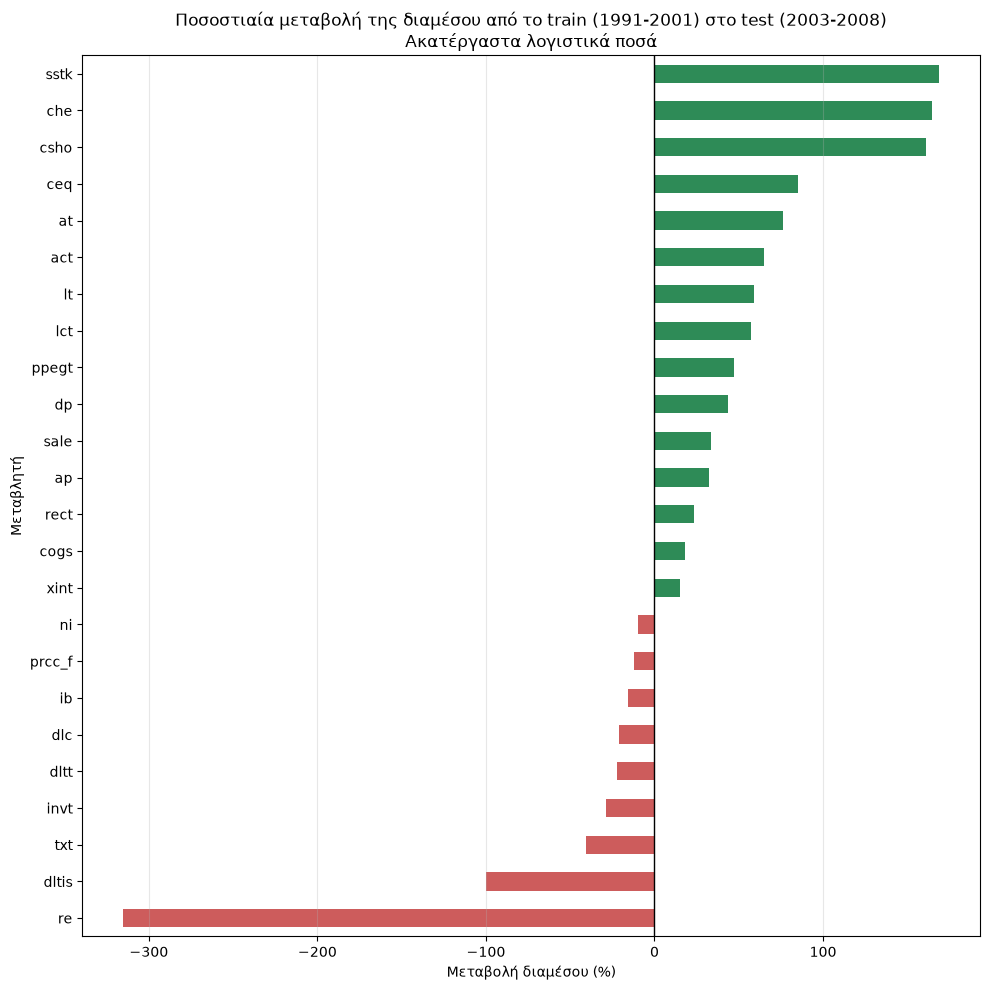

             train_median  test_median  difference
alt_x5              0.981        0.768      -0.213
reoa                0.036       -0.069      -0.105
alt_x1              0.203        0.175      -0.028
soft_assets         0.538        0.522      -0.016
EBIT                0.054        0.039      -0.015
ben_lvgi            1.012        1.006      -0.007
ch_rsst             0.033        0.027      -0.006
ben_dsri            0.988        0.982      -0.006
dch_rec             0.008        0.005      -0.003
issue               1.000        1.000       0.000
dch_inv             0.000        0.000       0.000
ch_cs               0.084        0.085       0.001
ben_gmi             0.997        0.999       0.002
ch_roa             -0.003        0.000       0.004
ben_tata           -0.041       -0.036       0.005
ben_sgi             1.087        1.095       0.008
dpi                 0.965        0.978       0.013
alt_x4              2.015        2.455       0.440


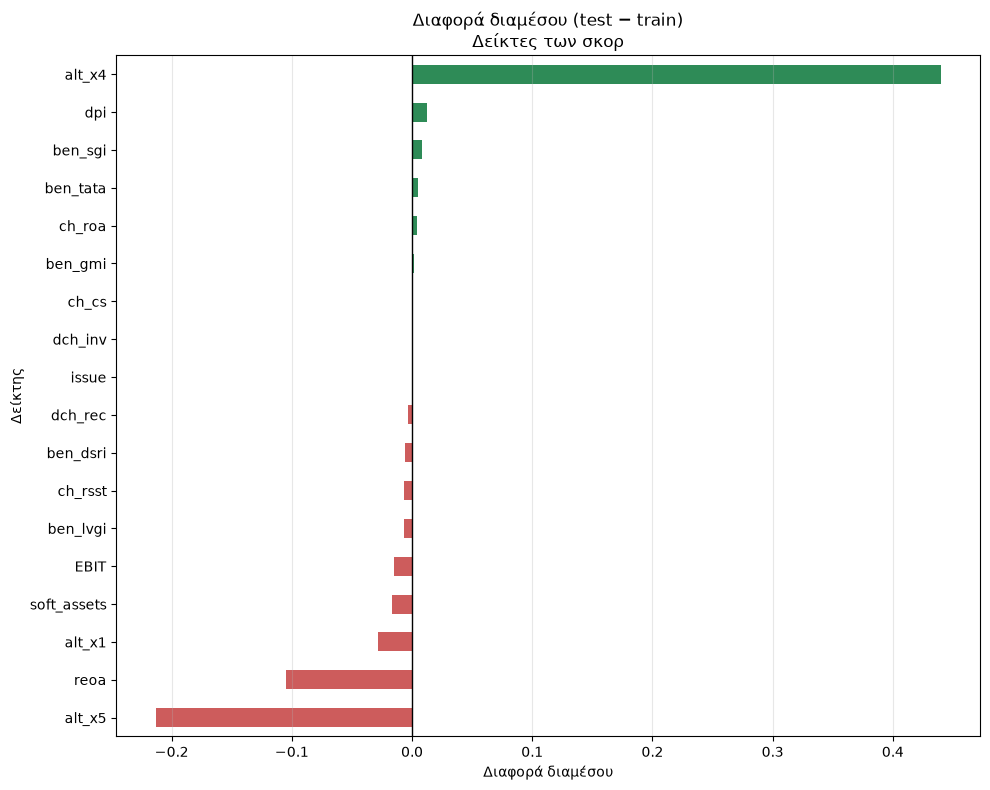

In [162]:
#  Ποσοστιαία μεταβολή raw μεταβλητών: διάμεσος σε train και test
raw_median = pd.DataFrame({
    'train_median': train[raw_cols].median(),
    'test_median':  test[raw_cols].median(),
})

# Μεταβλητές με διάμεσο 0 στο train (π.χ. ivst, pstk, txp) δεν μπορούν να
# μετρηθούν σε ποσοστό (διαίρεση με το 0), οπότε εξαιρούνται από το διάγραμμα
raw_median = raw_median[raw_median['train_median'] != 0]

raw_median['pct_change'] = (raw_median['test_median'] / raw_median['train_median'] - 1) * 100
raw_median = raw_median.sort_values('pct_change')
print(raw_median.round(1))

# Πράσινο αν αυξήθηκε στο test, κόκκινο αν μειώθηκε
colors = ['seagreen' if v > 0 else 'indianred' for v in raw_median['pct_change']]

ax = raw_median['pct_change'].plot(kind='barh', figsize=(10, 10), color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Ποσοστιαία μεταβολή της διαμέσου από το train (1991-2001) στο test (2003-2008)\nΑκατέργαστα λογιστικά ποσά')
ax.set_xlabel('Μεταβολή διαμέσου (%)')
ax.set_ylabel('Μεταβλητή')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


#  Δείκτες των σκορ: απόλυτη διαφορά 
ratio_median = pd.DataFrame({
    'train_median': train[score_cols].median(),
    'test_median':  test[score_cols].median(),
})
ratio_median['difference'] = ratio_median['test_median'] - ratio_median['train_median']
ratio_median = ratio_median.sort_values('difference')
print(ratio_median.round(3))

colors = ['seagreen' if v > 0 else 'indianred' for v in ratio_median['difference']]

ax = ratio_median['difference'].plot(kind='barh', figsize=(10, 8), color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Διαφορά διαμέσου (test − train)\nΔείκτες των σκορ')
ax.set_xlabel('Διαφορά διαμέσου')
ax.set_ylabel('Δείκτης')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

##### Παρατηρούμε πως τα raw δεδομένα παρουσιάζουν μεγάλες ποσοστιαίεες μεταβολές ανάμεσα στο train και το test ενώ οι δείκτες έχουν μικές διαφορές 

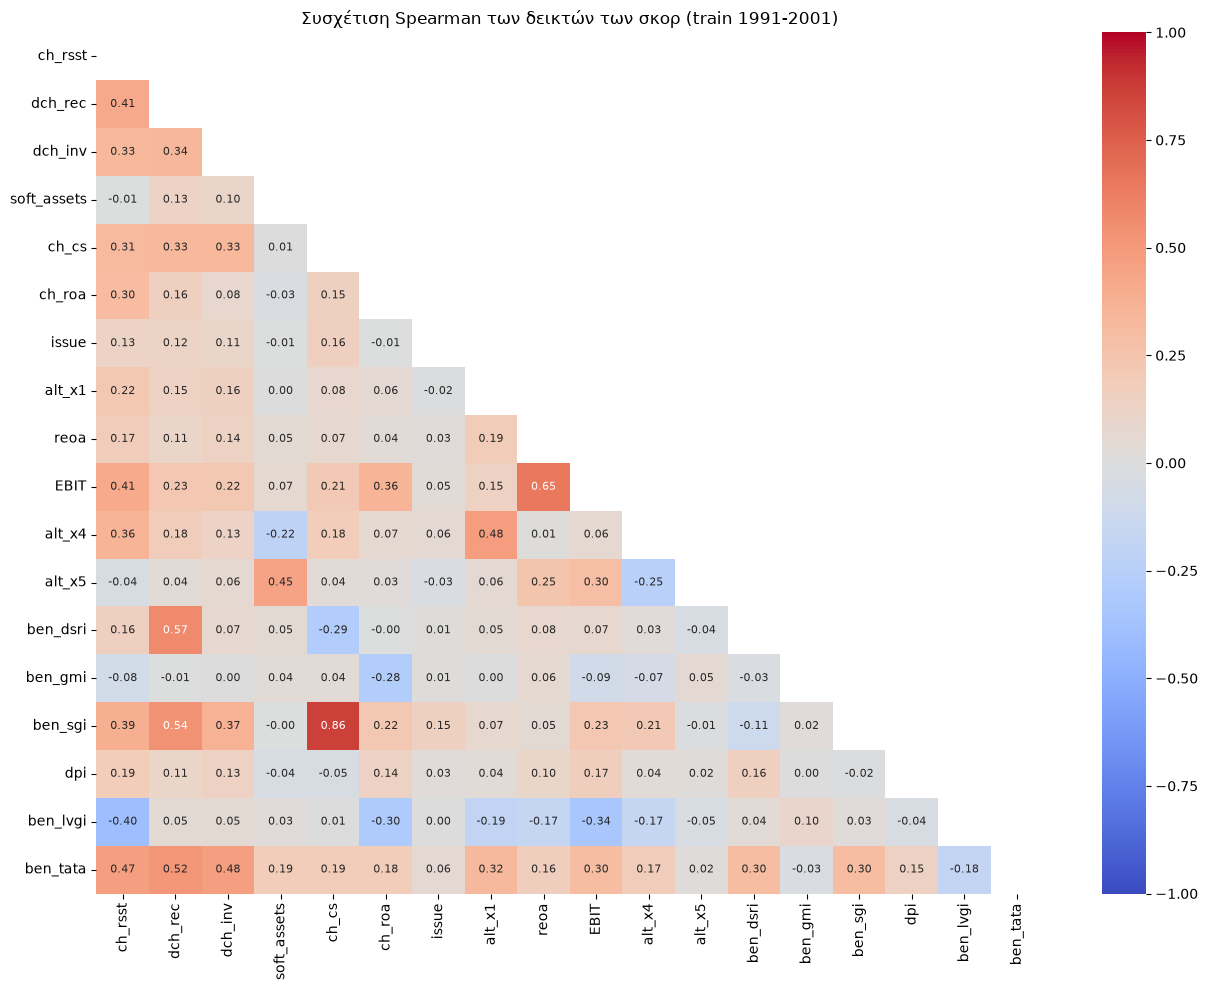

In [163]:
# Συσχέτιση Spearman των 18 δεικτών των σκορ - μόνο στο train
corr = train[score_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr,mask=mask, cmap='coolwarm', vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Συσχέτιση Spearman των δεικτών των σκορ (train 1991-2001)')
plt.tight_layout()
plt.savefig('diagramma_sysxetisi.png', dpi=300, bbox_inches='tight')
plt.show()

In [164]:
# Ζεύγη δεικτών με |συσχέτιση| >= 0.6
pairs = []
for i in range(len(score_cols)):
    for j in range(i + 1, len(score_cols)):
        value = corr.iloc[i, j]
        if abs(value) >= 0.6:
            pairs.append((score_cols[i], score_cols[j], round(value, 3)))

high_corr = pd.DataFrame(pairs, columns=['Δείκτης 1', 'Δείκτης 2', 'Spearman'])
print(high_corr.sort_values('Spearman', key=abs, ascending=False))

  Δείκτης 1 Δείκτης 2  Spearman
0     ch_cs   ben_sgi     0.862
1      reoa      EBIT     0.652


##### Οι δείκτες που παρσουσιάζουν τις υψηλότερες συσχετίσεις πάνω από 0,6 είναι η ch_cs με την ben_sgi δηλαδή η μεταβολή ταμειακών πωλήσεων με τον δείκτη αύξησης πωλήσεων και η reoa με τη EBIT δηλαδή τα αδιανέμητα κέρδη προς το σύνολο ενεργητικού με τα κερδη προ τόκων και φόρων προς το σύνολο του ενεργητικού. 
##### Οι υπόλοιποι δείκτες μεταφέρουν σε μεγάλο βαθμό διακριτή πληροφορία. Δεν αφαιρείται καμία μεταβλητή, καθώς το XGBoost δεν επηρεάζεται από την πολυσυγγραμμικότητα.

##### Όσον αφορά τα raw δεδομέαν δεν κάνουμε πίνακα συσχέτισης καθώς όλα τα νούμερα συνδέονται μεταξύ τους και θα είχαν όλα μεγάλες συσχετίσεις οπότε δεν θα έδειχνει χρήσιμη πληροφορία.

In [165]:
# Α2. Validation set - από τις αρχικές ετικέτες (df), όχι από το train
train_fit = df[df['fyear'].between(1991, 1999)].copy()
valid = df[df['fyear'].between(2000, 2001)].copy()

# Serial fraud για το ζευγάρι train_fit - validation
valid_cases = valid.loc[valid['misstate'] == 1, 'p_aaer'].unique()
serial_val = (train_fit['misstate'] == 1) & (train_fit['p_aaer'].isin(valid_cases))
print("Δόλιες χρονιές στο train_fit που ανήκουν σε υποθέσεις του validation:", serial_val.sum())
train_fit.loc[serial_val, 'misstate'] = 0

print("Train_fit μετά την αφαίρεση των serial fraud:", train_fit.shape, "| απάτες:", train_fit['misstate'].sum())
print("Valid:    ", valid.shape,     "| απάτες:", valid['misstate'].sum())

print("Υποθέσεις απάτης στο validation:", len(valid_cases))
print("Υποθέσεις απάτης και στο validation και στο train_fit:", train_fit.loc[serial_val, 'p_aaer'].nunique())

Δόλιες χρονιές στο train_fit που ανήκουν σε υποθέσεις του validation: 88
Train_fit μετά την αφαίρεση των serial fraud: (54052, 54) | απάτες: 244
Valid:     (13114, 54) | απάτες: 167
Υποθέσεις απάτης στο validation: 117
Υποθέσεις απάτης και στο validation και στο train_fit: 43


## **ΕΚΠΑΙΔΕΥΣΗ ΜΟΝΤΕΛΟΥ - ΠΑΡΑΛΛΑΓΕΣ**

### **RAW *VS*  RAW + SCORES**

In [166]:
# Μοντέλο 1: μόνο τα 28 raw
model_1_raw = XGBClassifier(random_state=RANDOM_STATE)
model_1_raw.fit(train_fit[raw_cols], train_fit['misstate'])

prediction_1_raw = model_1_raw.predict_proba(valid[raw_cols])[:, 1]
auc_1_raw = roc_auc_score(valid['misstate'], prediction_1_raw)
print("Raw - AUC validation:", round(auc_1_raw, 4))

Raw - AUC validation: 0.6403


In [167]:
# Μοντέλο 2: 28 raw + 18 δείκτες των σκορ
features_scores = raw_cols + score_cols
print("Πλήθος μεταβλητών:", len(features_scores))   # πρέπει να βγει 46

model_2_scores = XGBClassifier(random_state=RANDOM_STATE)
model_2_scores.fit(train_fit[features_scores], train_fit['misstate'])

prediction_2_scores = model_2_scores.predict_proba(valid[features_scores])[:, 1]
auc_2_scores = roc_auc_score(valid['misstate'], prediction_2_scores)
print("Raw + δείκτες - AUC validation:", round(auc_2_scores, 4))

Πλήθος μεταβλητών: 46
Raw + δείκτες - AUC validation: 0.6809


In [168]:
# Σύγκριση
diff = auc_model_2_scores - auc_model_1_raw
print("Raw:           ", round(auc_model_1_raw, 4))
print("Raw + δείκτες: ", round(auc_model_2_scores, 4))
print("Διαφορά:       ", round(diff, 4))

Raw:            0.6403
Raw + δείκτες:  0.6809
Διαφορά:        0.0406


#### Άρα οι **δείκτες** των σκορ **αυξάνουν** το AUC και συνεπώς τις κρατάμε στο μοντέλο και οι επόμενες παραλλαγές που αθα ακολουθήσουν θα εφαρμοστους στο μοντέλο που υπερίσχυσε δηλαδή raw + scores

###  **RAW SCALED *VS* RAW SCALED + SCORES**

In [169]:
# Διαίρεση των raw ποσών με το σύνολο ενεργητικού (at)
keep_as_is = ['at', 'prcc_f', 'csho']    # αυτά δεν διαιρούνται
scaled_cols = []                          

for c in raw_cols:
    if c not in keep_as_is:
        for d in [train_fit, valid, train, test]:
            d[c + '_at'] = d[c] / d['at']
        scaled_cols.append(c + '_at')

# Διαίρεση με 0 -> άπειρο -> το κάνουμε κενή τιμή
for d in [train_fit, valid, train, test]:
    d[scaled_cols] = d[scaled_cols].replace([np.inf, -np.inf], np.nan)

raw_scaled = scaled_cols + keep_as_is
print("Πλήθος διαιρεμένων:", len(scaled_cols))        # πρέπει να είναι 25
print("Πλήθος raw_scaled:", len(raw_scaled))          # πρέπει να ειναι 28
print(train_fit[['rect', 'at', 'rect_at']].head())

Πλήθος διαιρεμένων: 25
Πλήθος raw_scaled: 28
          rect       at   rect_at
4582    89.781  395.351  0.227092
38301  163.359  670.559  0.243616
4583     8.205   35.559  0.230743
9295     8.944   41.976  0.213074
14265   12.983   63.997  0.202869


In [170]:
# Μοντέλο με τα raw διαιρεμένα με το ενεργητικό + 18 δείκτες
features_scaled = raw_scaled + score_cols
print("Πλήθος μεταβλητών:", len(features_scaled))   # πρέπει 46

model_3_scaled_scores = XGBClassifier(random_state=RANDOM_STATE)
model_3_scaled_scores.fit(train_fit[features_scaled], train_fit['misstate'])

prediction_3_scaled_scores = model_3_scaled_scores.predict_proba(valid[features_scaled])[:, 1]
auc_3_scaled_scores = roc_auc_score(valid['misstate'], prediction_3_scaled_scores)

print("Raw + δείκτες (Β1):              ", round(auc_2_scores, 4))
print("Raw scaled + δείκτες:            ", round(auc_3_scaled_scores, 4))
print("Διαφορά:                         ", round(auc_3_scaled_scores - auc_2_scores, 4))

Πλήθος μεταβλητών: 46


Raw + δείκτες (Β1):               0.6809
Raw scaled + δείκτες:             0.7193
Διαφορά:                          0.0384


In [171]:
# Έλεγχος H1 με διαιρεμένα raw: μόνο τα 28 raw_scaled, χωρίς δείκτες

model_4_scaled_raw = XGBClassifier(random_state=RANDOM_STATE)
model_4_scaled_raw.fit(train_fit[raw_scaled], train_fit['misstate'])

prediction_4_scaled = model_4_scaled_raw.predict_proba(valid[raw_scaled])[:, 1]
auc_4_scaled_raw = roc_auc_score(valid['misstate'], prediction_4_scaled)

print("Raw scaled:          ",       round(auc_4_scaled_raw, 4))
print("Raw scaled + δείκτες:", round(auc_3_scaled_scores, 4))
print("Διαφορά:             ", round(auc_3_scaled_scores - auc_4_scaled_raw, 4))

Raw scaled:           0.7329
Raw scaled + δείκτες: 0.7193
Διαφορά:              -0.0136


#### Παρατηρούμε πως οι δείκτες βελτίωσαν το μοντέλο όταν τα δεδομένα δεν ήταν scaled ενώ όταν διαιρέθηκαν με το σύνολο του ενεργητικού το μοντέλο **raw scaled + scores είχε ελαφρώς χαμηλότερο σκορ από το raw scaled**